# Session 2 (Writing, Juggling, Throwing): segment comparisons

The recording has **six segments** (the recording was paused for an impedance check between
tasks), forming three pairs. Within each pair, the second task is expected to be harder.

| Segment | Task | Pair |
|---|---|---|
| 1 | Writing your name, dominant hand (right) | A: writing |
| 2 | Writing your name, non-dominant hand (left) | A: writing |
| 3 | Juggling 1 packet (easy) | B: juggling |
| 4 | Juggling 3 packets (difficult) | B: juggling |
| 5 | Throwing, dominant hand (right) | C: throwing |
| 6 | Throwing, non-dominant hand (left) | C: throwing |

**Hypothesis (as in Session 1):** the harder task in each pair puts more load on working
memory, so relative theta at **Fz** should be higher and parietal alpha lower.

**Differences from Session 1:**
- Sampled at **1000 Hz** (Session 1 was 500 Hz). All code adapts to the sampling rate.
- Bad electrodes: **P3 and O2** have large electrode pops again (the same two as in Session
  1, so they're likely faulty on this cap). C4 is fine here, which matters because C3/C4 sit
  over the motor areas for the right/left hand.
- **Juggling and throwing involve whole-body movement**, which a standard EEG cap picks up
  as large artifacts. The data-quality check below shows how much usable data each task has,
  and the statistical test is only run where both segments have enough clean windows.
- No stimulus markers were recorded, so there is no ERP/P300 section.
- **Relative power is a band's share of 4–40 Hz, leaving out delta (1–4 Hz).** Delta here is
  dominated by slow drift and movement, and its share drops in later segments. With delta
  included, that drop pushes every other band's share up and makes theta look higher even
  when it isn't (this happened in the first version of the Session 1 analysis).

**Statistics:** p-values are descriptive only. Windows cut from one continuous recording are
not independent samples, so treating them as such (pseudoreplication) overstates certainty.
Real inference needs several blocks per condition or several people.

**Caveat (all pairs):** the harder task always came second, so time on task and fatigue
are confounded with difficulty. This is one person in one session.

Shared analysis code lives in `processing/analysis.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "processing").is_dir():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from processing import load_session
from processing.analysis import (
    band_filter, fz_workload_test, plot_quality, plot_relative_bars, plot_segments,
    plot_spectra, window_spectra,
)

plt.rcParams["figure.dpi"] = 72   # keeps the notebook size manageable with 24-row figures

SESSION_DIR = REPO_ROOT / "data" / "Session 2_ Writing_Juggling_Throwing"
TASKS = [
    "1: Write, right (dominant)", "2: Write, left (non-dominant)",
    "3: Juggle 1 packet (easy)", "4: Juggle 3 packets (difficult)",
    "5: Throw, right (dominant)", "6: Throw, left (non-dominant)",
]
PAIRS = {"A: Writing": (0, 1), "B: Juggling": (2, 3), "C: Throwing": (4, 5)}
BAD_CHANNELS = ["P3", "O2"]       # electrode pops in segments 1–2 (and in Session 1)

In [2]:
session = load_session(SESSION_DIR)
segments = session.segments
assert len(segments) == len(TASKS), len(segments)
print(f"Sampling rate: {session.sfreq:g} Hz; channels: {', '.join(session.ch_names)}")
for task, info, seg in zip(TASKS, session.segment_info, segments):
    print(f"Segment {task:34} {seg.times[-1]:7.1f} s, started {info.start_time:%H:%M:%S} UTC")

Sampling rate: 1000 Hz; channels: Fp1, Fp2, F9, F7, F3, Fz, F4, F8, F10, T9, T7, C3, C4, T8, T10, P9, P7, P3, Pz, P4, P8, P10, O1, O2
Segment 1: Write, right (dominant)           300.8 s, started 21:58:01 UTC
Segment 2: Write, left (non-dominant)        299.5 s, started 22:03:49 UTC
Segment 3: Juggle 1 packet (easy)             61.9 s, started 22:13:41 UTC
Segment 4: Juggle 3 packets (difficult)       62.1 s, started 22:15:39 UTC
Segment 5: Throw, right (dominant)            62.6 s, started 22:22:36 UTC
Segment 6: Throw, left (non-dominant)         66.5 s, started 22:24:19 UTC


## 1. Data quality: how much clean data does each task have?

Each segment is cleaned as in Session 1 (1 Hz high-pass, 60 Hz notch) and cut into 2 s
windows. A window counts as clean on a channel if that channel swings less than 150 µV.

**Why this plot:** movement adds large artifacts, so before comparing tasks we need to know which channels and tasks still have enough clean EEG to trust.

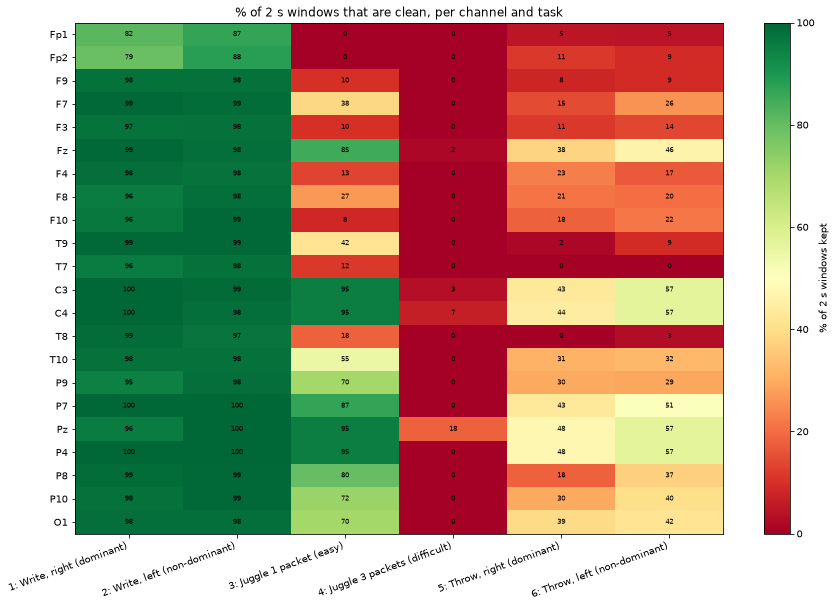

In [3]:
spectra = [window_spectra(seg, BAD_CHANNELS) for seg in segments]
plot_quality(spectra, TASKS, "% of 2 s windows that are clean, per channel and task")

## 2. Pair A: Writing: segment 1 vs segment 2

Segment 1 on the left, segment 2 on the right. In the filtered plots each channel's
two panels share a y-axis so amplitudes can be compared.

In [4]:
pair_writing = [segments[0], segments[1]]
labels_writing = [TASKS[0], TASKS[1]]

### 2.1 Original (unfiltered) data

**Why this plot:** check signal quality before any processing: drift, noisy channels, and movement or blink artifacts that filtering could hide or smear.

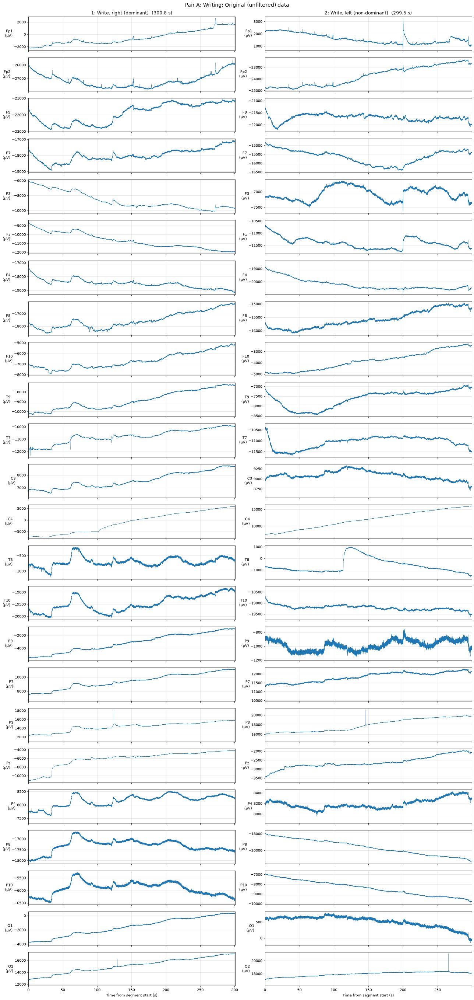

In [5]:
plot_segments(pair_writing, labels_writing, "Pair A: Writing: Original (unfiltered) data", sharey_rows=False)

### 2.2 Theta band (4–8 Hz)

**Why this plot:** frontal theta rises with task difficulty and working memory load, so higher theta in the harder task would suggest it was more demanding.

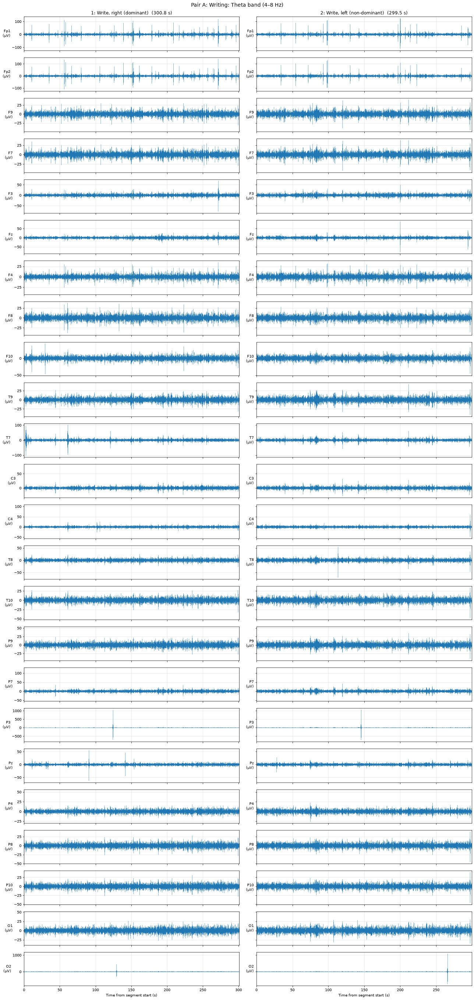

In [6]:
plot_segments([band_filter(s, 4, 8) for s in pair_writing], labels_writing, "Pair A: Writing: Theta band (4–8 Hz)")

### 2.3 Alpha band (8–13 Hz)

**Why this plot:** alpha weakens when the brain is engaged with a task, so lower alpha in the harder task would suggest it demanded more attention.

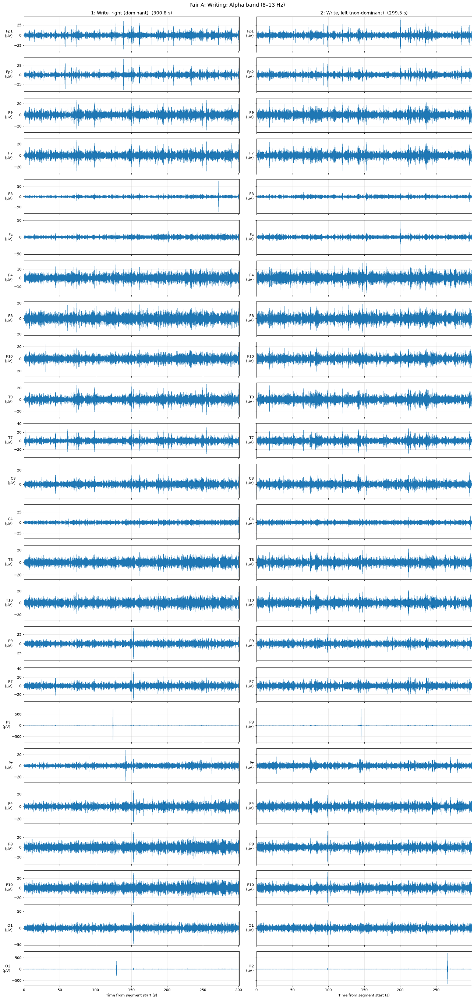

In [7]:
plot_segments([band_filter(s, 8, 13) for s in pair_writing], labels_writing, "Pair A: Writing: Alpha band (8–13 Hz)")

### 2.4 Beta band (13–30 Hz)

**Why this plot:** beta mostly tracks movement and muscle activity in these tasks (over C3/C4 it drops whenever you move, and muscle activity has beta-range peaks), so it shows how differently the two tasks were performed physically. It is a confound to watch, not a measure of effort.

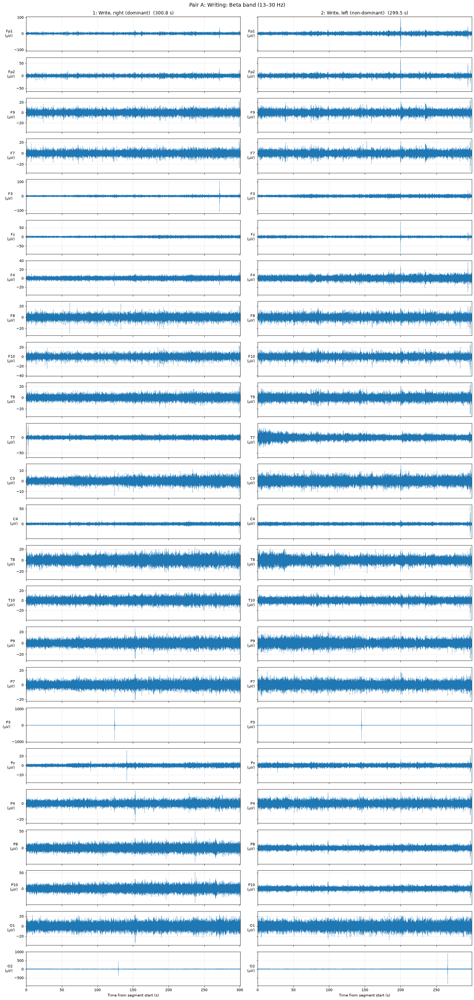

In [8]:
plot_segments([band_filter(s, 13, 30) for s in pair_writing], labels_writing, "Pair A: Writing: Beta band (13–30 Hz)")

### 2.5 Gamma band (30–100 Hz, 60 Hz notch)

**Why this plot:** gamma on the scalp is mostly muscle activity (forehead, jaw, neck, eye muscles), so it shows how much muscle tension each task produced. It is a confound to watch, not a measure of effort.

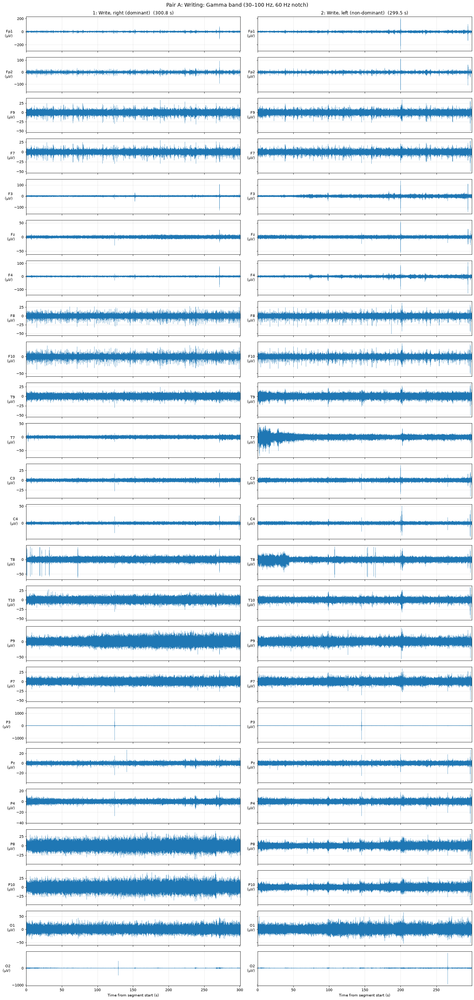

In [9]:
plot_segments([band_filter(s, 30, 100, notch=60) for s in pair_writing], labels_writing, "Pair A: Writing: Gamma band (30–100 Hz, 60 Hz notch)")

### 2.6 Frequency decomposition (FFT)

Welch's method, as in Session 1: 2 s Hann windows with 50% overlap (0.5 Hz resolution),
averaged over the clean windows. Channels with fewer than half their windows clean are
marked in red (spectra) or greyed out (bars).

**Why these plots:** the spectra show which frequencies carry the power in each task; the
bars and the Fz comparison check whether theta rises (and alpha falls) in the harder task
(p-values descriptive only).

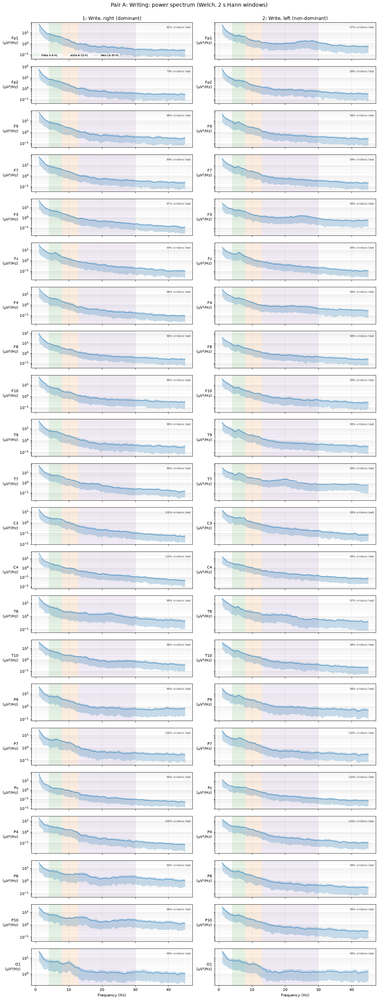

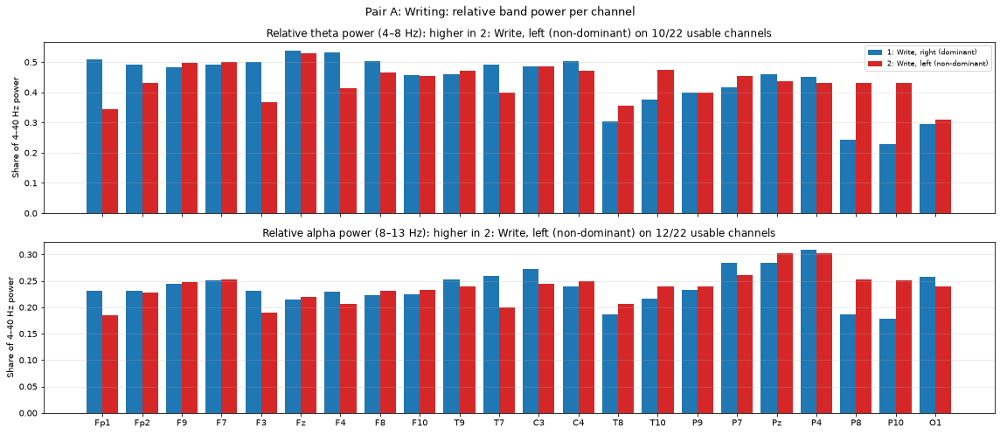

Absolute theta at Fz (µV²)   1: Write, right (dominant): median 14.980 (n=149); 2: Write, left (non-dominant): median 12.587 (n=146); descriptive p = 0.93
Relative theta at Fz         1: Write, right (dominant): median 0.530 (n=149); 2: Write, left (non-dominant): median 0.474 (n=146); descriptive p = 0.98
Fz theta / Pz alpha          1: Write, right (dominant): median 4.078 (n=143); 2: Write, left (non-dominant): median 2.932 (n=145); descriptive p = 1


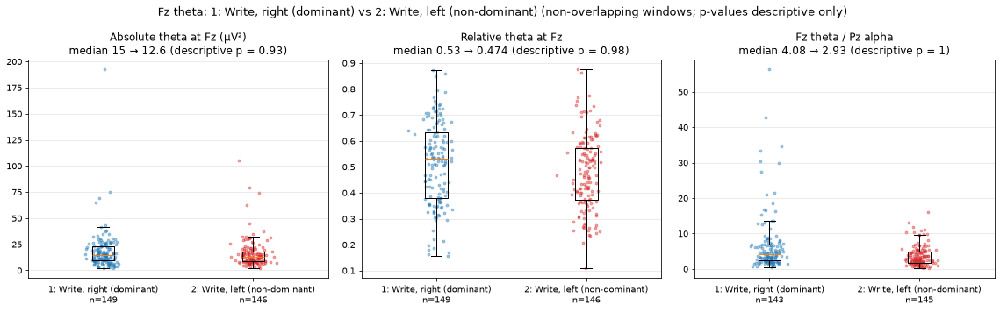

In [10]:
sp_writing = [spectra[0], spectra[1]]
plot_spectra(sp_writing, labels_writing, "Pair A: Writing: power spectrum (Welch, 2 s Hann windows)")
plot_relative_bars(sp_writing, labels_writing, "Pair A: Writing: relative band power per channel")
res_writing = fz_workload_test(pair_writing, labels_writing, BAD_CHANNELS)

## 3. Pair B: Juggling: segment 3 vs segment 4

Segment 3 on the left, segment 4 on the right. In the filtered plots each channel's
two panels share a y-axis so amplitudes can be compared.

In [11]:
pair_juggling = [segments[2], segments[3]]
labels_juggling = [TASKS[2], TASKS[3]]

### 3.1 Original (unfiltered) data

**Why this plot:** check signal quality before any processing: drift, noisy channels, and movement or blink artifacts that filtering could hide or smear.

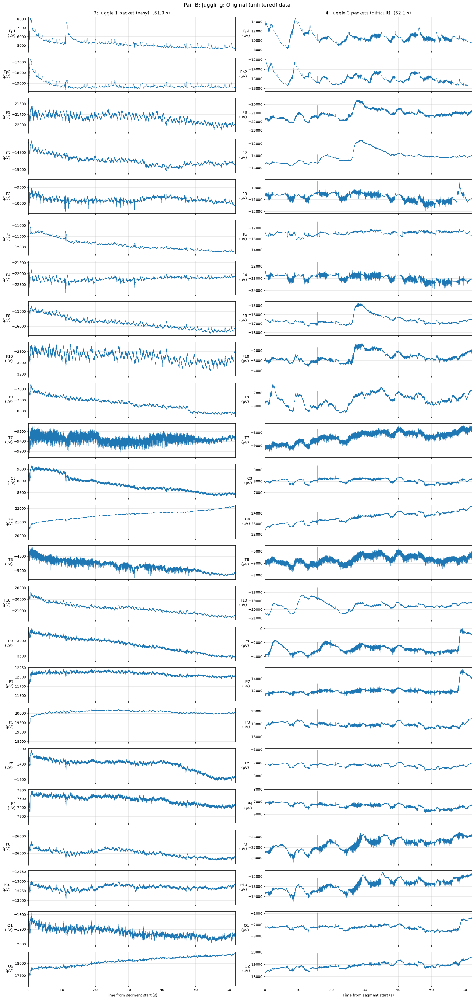

In [12]:
plot_segments(pair_juggling, labels_juggling, "Pair B: Juggling: Original (unfiltered) data", sharey_rows=False)

### 3.2 Theta band (4–8 Hz)

**Why this plot:** frontal theta rises with task difficulty and working memory load, so higher theta in the harder task would suggest it was more demanding.

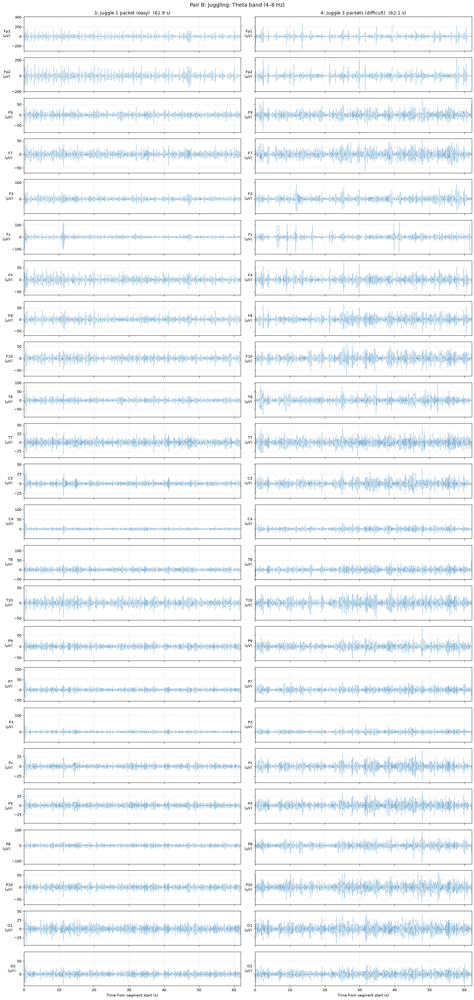

In [13]:
plot_segments([band_filter(s, 4, 8) for s in pair_juggling], labels_juggling, "Pair B: Juggling: Theta band (4–8 Hz)")

### 3.3 Alpha band (8–13 Hz)

**Why this plot:** alpha weakens when the brain is engaged with a task, so lower alpha in the harder task would suggest it demanded more attention.

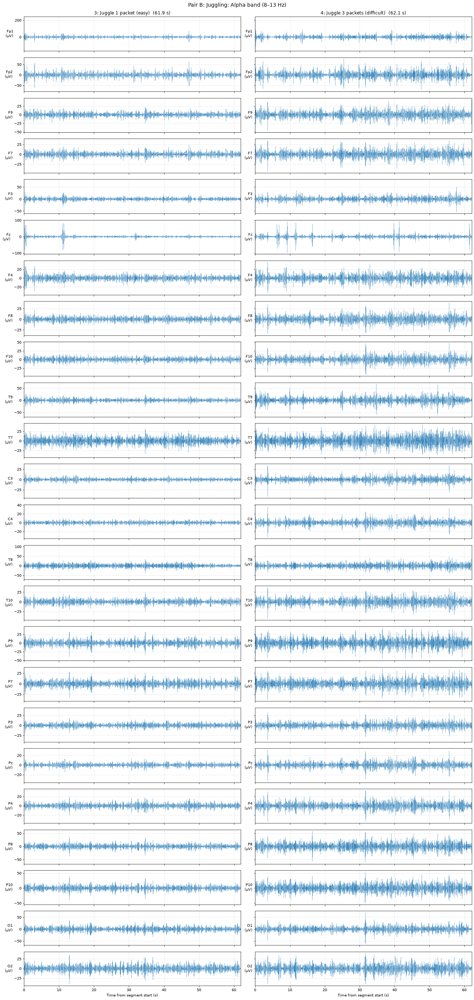

In [14]:
plot_segments([band_filter(s, 8, 13) for s in pair_juggling], labels_juggling, "Pair B: Juggling: Alpha band (8–13 Hz)")

### 3.4 Beta band (13–30 Hz)

**Why this plot:** beta mostly tracks movement and muscle activity in these tasks (over C3/C4 it drops whenever you move, and muscle activity has beta-range peaks), so it shows how differently the two tasks were performed physically. It is a confound to watch, not a measure of effort.

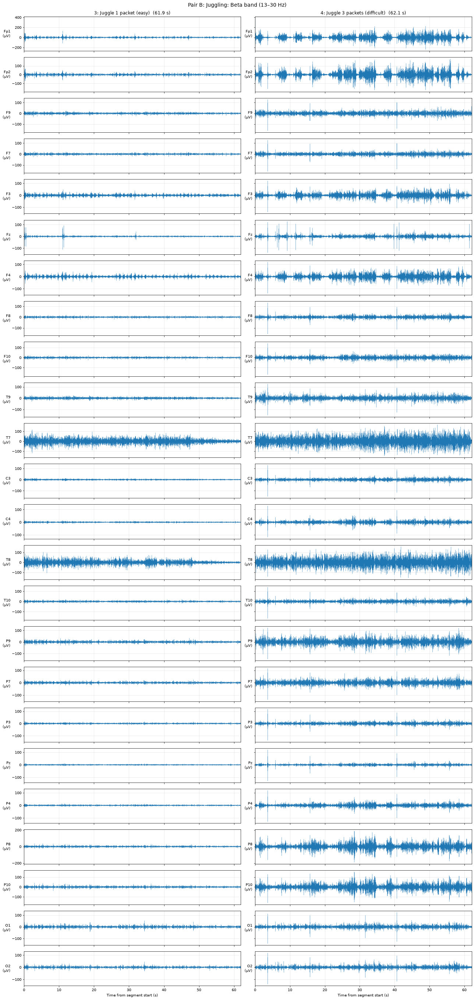

In [15]:
plot_segments([band_filter(s, 13, 30) for s in pair_juggling], labels_juggling, "Pair B: Juggling: Beta band (13–30 Hz)")

### 3.5 Gamma band (30–100 Hz, 60 Hz notch)

**Why this plot:** gamma on the scalp is mostly muscle activity (forehead, jaw, neck, eye muscles), so it shows how much muscle tension each task produced. It is a confound to watch, not a measure of effort.

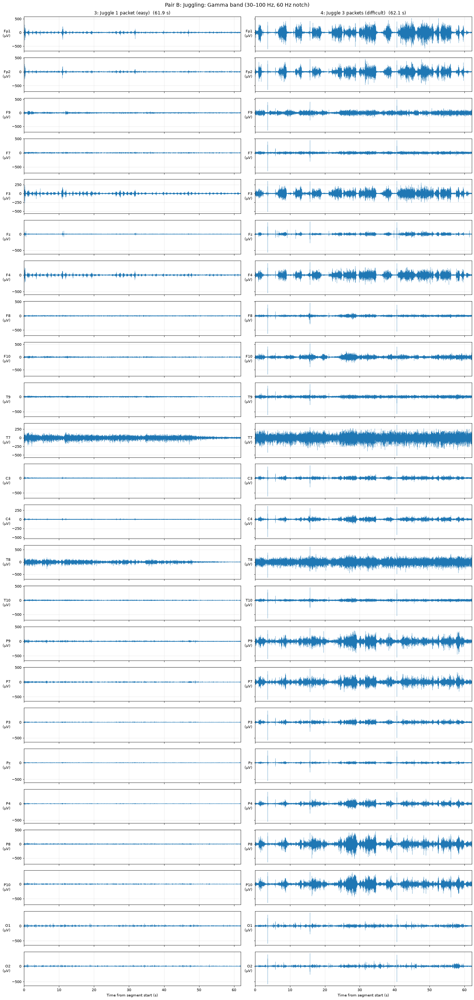

In [16]:
plot_segments([band_filter(s, 30, 100, notch=60) for s in pair_juggling], labels_juggling, "Pair B: Juggling: Gamma band (30–100 Hz, 60 Hz notch)")

### 3.6 Frequency decomposition (FFT)

Welch's method, as in Session 1: 2 s Hann windows with 50% overlap (0.5 Hz resolution),
averaged over the clean windows. Channels with fewer than half their windows clean are
marked in red (spectra) or greyed out (bars).

**Why these plots:** the spectra show which frequencies carry the power in each task; the
bars and the Fz comparison check whether theta rises (and alpha falls) in the harder task
(p-values descriptive only).

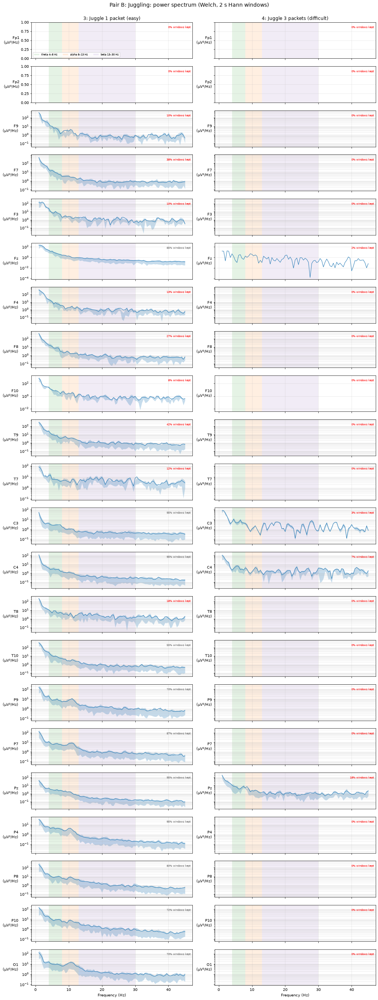

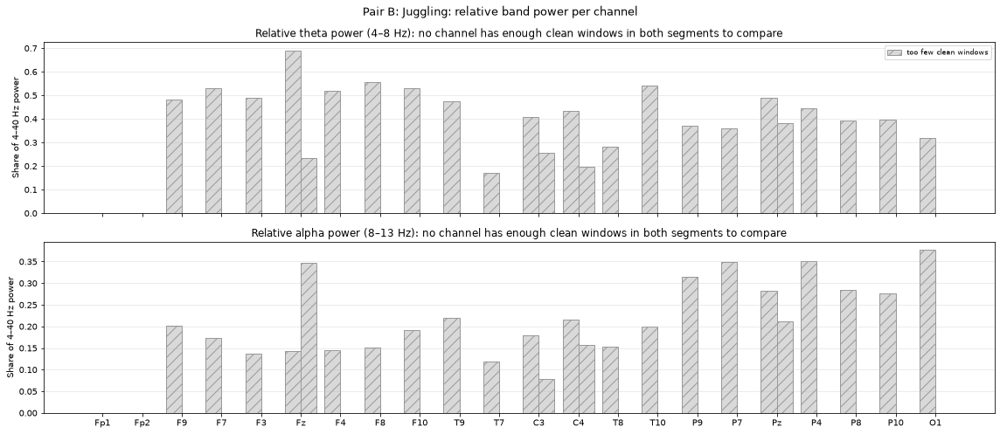

Not enough clean Fz windows to test: 3: Juggle 1 packet (easy) n=25, 4: Juggle 3 packets (difficult) n=0 (need ≥20 each). Skipped.


In [17]:
sp_juggling = [spectra[2], spectra[3]]
plot_spectra(sp_juggling, labels_juggling, "Pair B: Juggling: power spectrum (Welch, 2 s Hann windows)")
plot_relative_bars(sp_juggling, labels_juggling, "Pair B: Juggling: relative band power per channel")
res_juggling = fz_workload_test(pair_juggling, labels_juggling, BAD_CHANNELS)

## 4. Pair C: Throwing: segment 5 vs segment 6

Segment 5 on the left, segment 6 on the right. In the filtered plots each channel's
two panels share a y-axis so amplitudes can be compared.

In [18]:
pair_throwing = [segments[4], segments[5]]
labels_throwing = [TASKS[4], TASKS[5]]

### 4.1 Original (unfiltered) data

**Why this plot:** check signal quality before any processing: drift, noisy channels, and movement or blink artifacts that filtering could hide or smear.

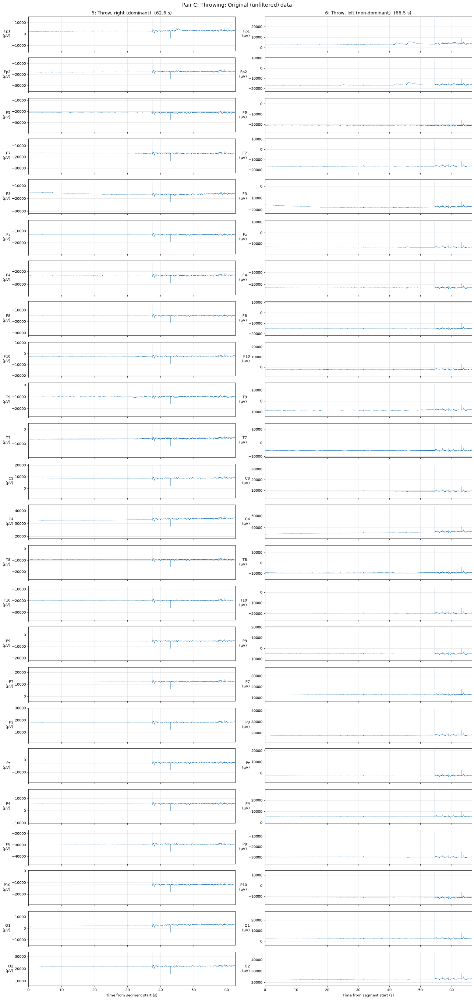

In [19]:
plot_segments(pair_throwing, labels_throwing, "Pair C: Throwing: Original (unfiltered) data", sharey_rows=False)

### 4.2 Theta band (4–8 Hz)

**Why this plot:** frontal theta rises with task difficulty and working memory load, so higher theta in the harder task would suggest it was more demanding.

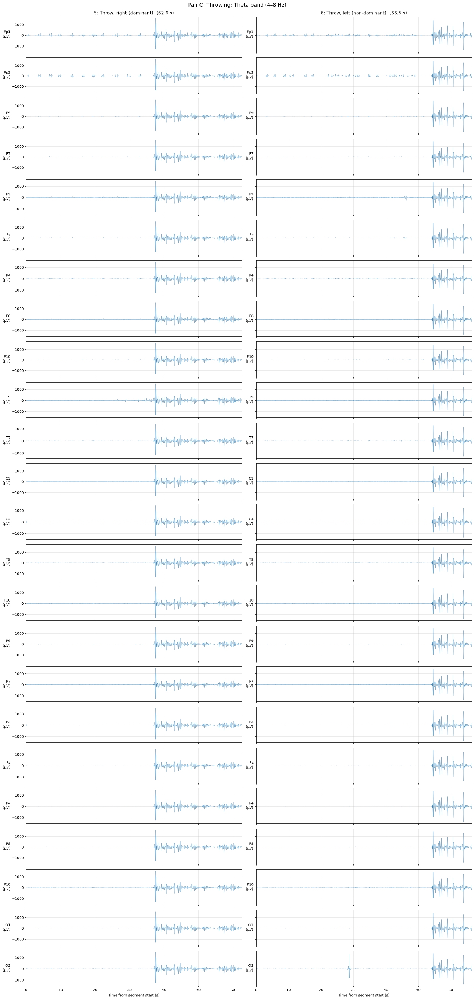

In [20]:
plot_segments([band_filter(s, 4, 8) for s in pair_throwing], labels_throwing, "Pair C: Throwing: Theta band (4–8 Hz)")

### 4.3 Alpha band (8–13 Hz)

**Why this plot:** alpha weakens when the brain is engaged with a task, so lower alpha in the harder task would suggest it demanded more attention.

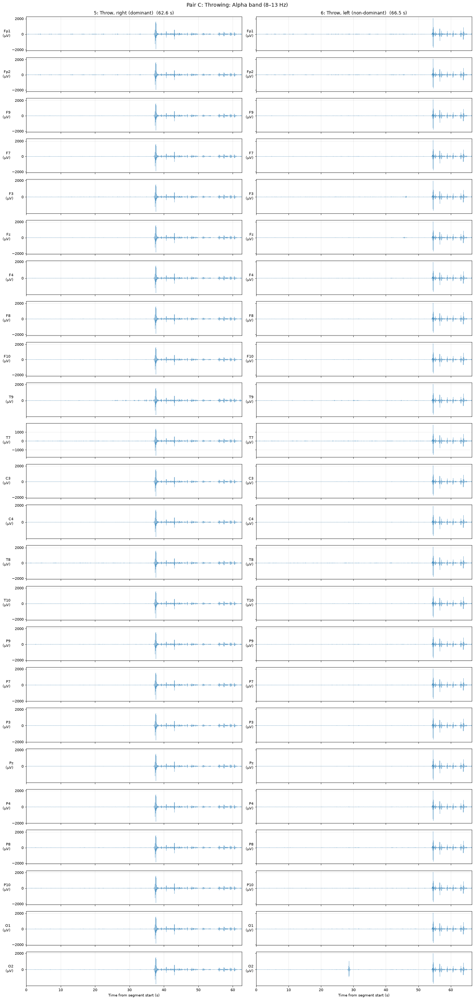

In [21]:
plot_segments([band_filter(s, 8, 13) for s in pair_throwing], labels_throwing, "Pair C: Throwing: Alpha band (8–13 Hz)")

### 4.4 Beta band (13–30 Hz)

**Why this plot:** beta mostly tracks movement and muscle activity in these tasks (over C3/C4 it drops whenever you move, and muscle activity has beta-range peaks), so it shows how differently the two tasks were performed physically. It is a confound to watch, not a measure of effort.

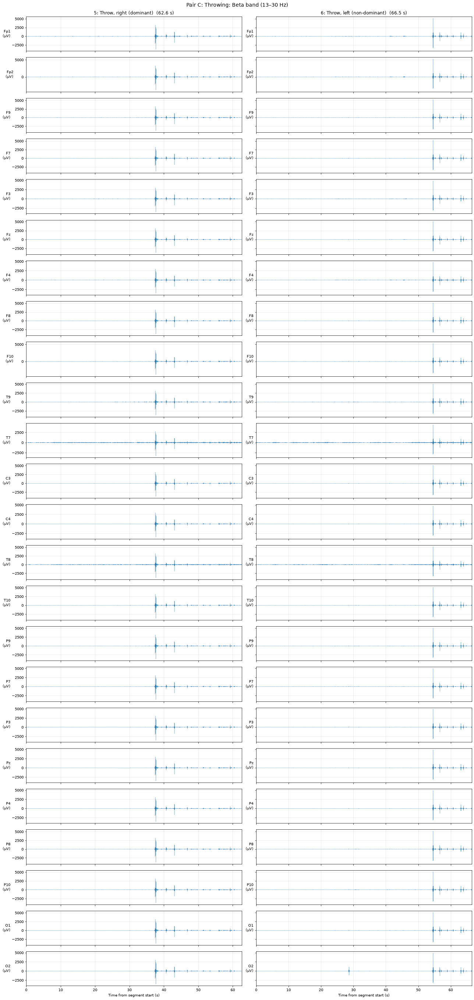

In [22]:
plot_segments([band_filter(s, 13, 30) for s in pair_throwing], labels_throwing, "Pair C: Throwing: Beta band (13–30 Hz)")

### 4.5 Gamma band (30–100 Hz, 60 Hz notch)

**Why this plot:** gamma on the scalp is mostly muscle activity (forehead, jaw, neck, eye muscles), so it shows how much muscle tension each task produced. It is a confound to watch, not a measure of effort.

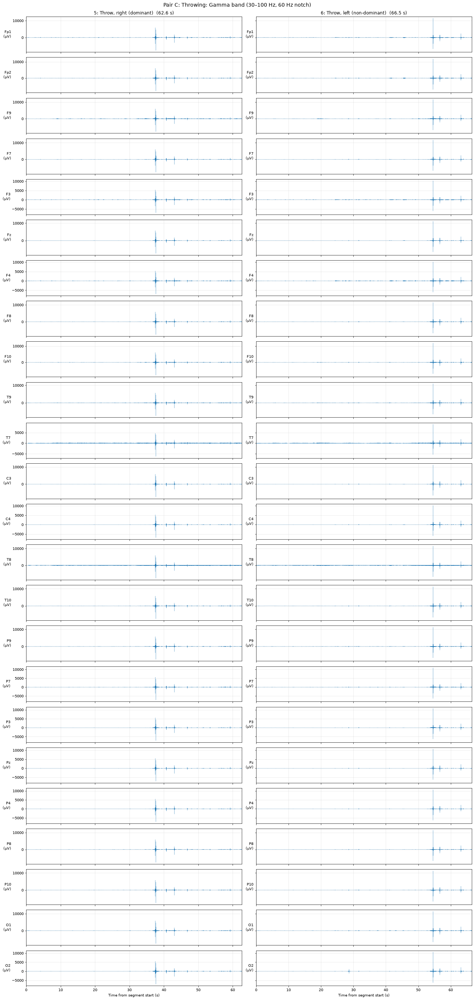

In [23]:
plot_segments([band_filter(s, 30, 100, notch=60) for s in pair_throwing], labels_throwing, "Pair C: Throwing: Gamma band (30–100 Hz, 60 Hz notch)")

### 4.6 Frequency decomposition (FFT)

Welch's method, as in Session 1: 2 s Hann windows with 50% overlap (0.5 Hz resolution),
averaged over the clean windows. Channels with fewer than half their windows clean are
marked in red (spectra) or greyed out (bars).

**Why these plots:** the spectra show which frequencies carry the power in each task; the
bars and the Fz comparison check whether theta rises (and alpha falls) in the harder task
(p-values descriptive only).

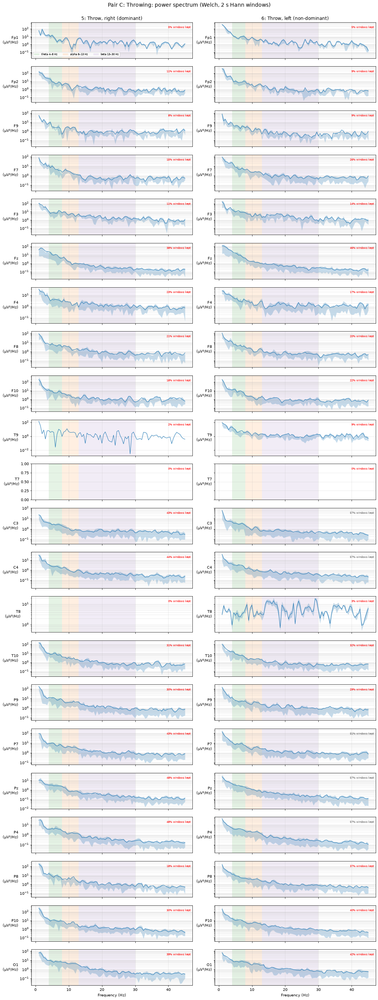

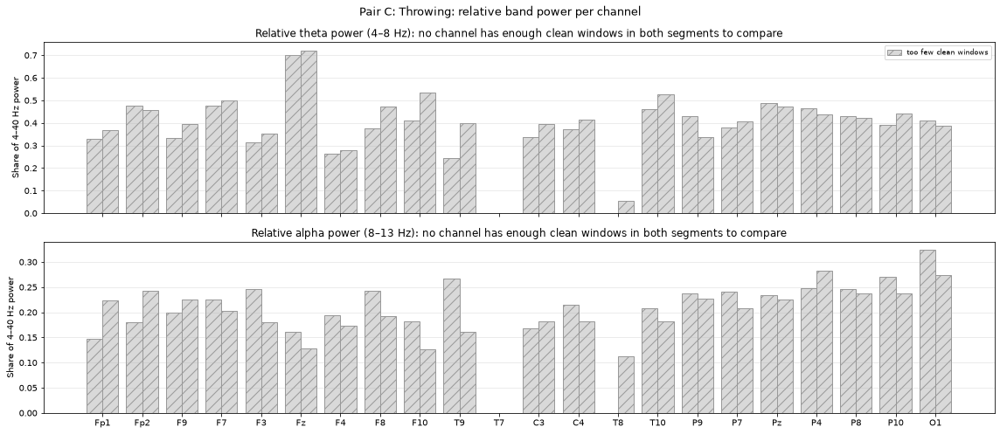

Not enough clean Fz windows to test: 5: Throw, right (dominant) n=11, 6: Throw, left (non-dominant) n=14 (need ≥20 each). Skipped.


In [24]:
sp_throwing = [spectra[4], spectra[5]]
plot_spectra(sp_throwing, labels_throwing, "Pair C: Throwing: power spectrum (Welch, 2 s Hann windows)")
plot_relative_bars(sp_throwing, labels_throwing, "Pair C: Throwing: relative band power per channel")
res_throwing = fz_workload_test(pair_throwing, labels_throwing, BAD_CHANNELS)

## 5. Overview: Fz theta and parietal alpha across all six tasks

Relative theta at Fz and relative alpha (shares of 4–40 Hz) averaged over the parietal channels (P7, Pz, P4, P8),
per task. Bars are hatched where fewer than half of the windows were clean on those channels.

**Why this plot:** it puts all six tasks on one scale, so the difficulty pattern (or its absence) can be seen across the whole session at once.

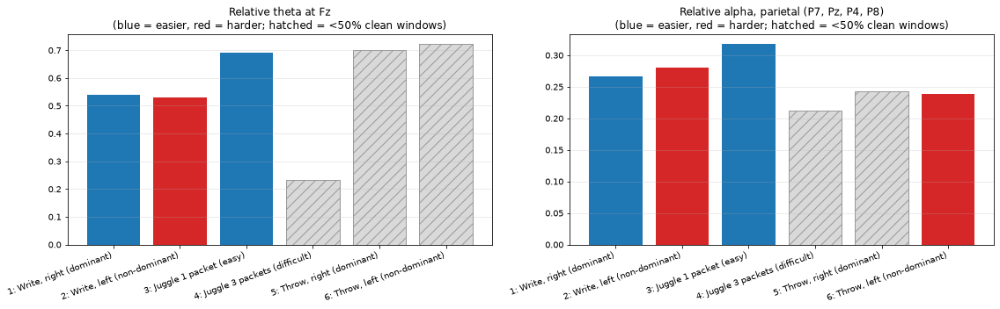

1: Write, right (dominant)         rel theta Fz 0.539 (Fz 99% clean)   rel alpha parietal 0.266
2: Write, left (non-dominant)      rel theta Fz 0.530 (Fz 98% clean)   rel alpha parietal 0.280
3: Juggle 1 packet (easy)          rel theta Fz 0.691 (Fz 85% clean)   rel alpha parietal 0.317
4: Juggle 3 packets (difficult)    rel theta Fz 0.234 (Fz 2% clean)   rel alpha parietal 0.212
5: Throw, right (dominant)         rel theta Fz 0.701 (Fz 38% clean)   rel alpha parietal 0.242
6: Throw, left (non-dominant)      rel theta Fz 0.721 (Fz 46% clean)   rel alpha parietal 0.238


In [25]:
from processing.analysis import BANDS, relative_power

PARIETAL = ["P7", "Pz", "P4", "P8"]
chs = spectra[0][2]
fz, par = chs.index("Fz"), [chs.index(c) for c in PARIETAL]
theta_fz = [relative_power(s, BANDS["theta"])[fz] for s in spectra]
alpha_par = [np.nanmean(relative_power(s, BANDS["alpha"])[par]) for s in spectra]
ok_fz = [s[3][fz] >= 0.5 for s in spectra]
ok_par = [np.mean(s[3][par]) >= 0.5 for s in spectra]

colors = ["C0", "C3"] * 3
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, vals, ok, title in [(axes[0], theta_fz, ok_fz, "Relative theta at Fz"),
                            (axes[1], alpha_par, ok_par, f"Relative alpha, parietal ({', '.join(PARIETAL)})")]:
    for i, (v, good) in enumerate(zip(vals, ok)):
        ax.bar(i, np.nan_to_num(v), color=colors[i] if good else "0.85",
               hatch=None if good else "//", edgecolor="0.6" if not good else None)
    ax.set_xticks(range(6), TASKS, rotation=20, ha="right")
    ax.set_title(title + "\n(blue = easier, red = harder; hatched = <50% clean windows)")
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()
for task, t, a, k in zip(TASKS, theta_fz, alpha_par, [s[3][fz] for s in spectra]):
    print(f"{task:34} rel theta Fz {t:.3f} (Fz {100 * k:.0f}% clean)   rel alpha parietal {a:.3f}")

## 6. Cleaned analysis: ASR + ICA + theta/alpha above the 1/f background

Same idea as section 8 of the Session 1 notebook, plus ASR for the movement tasks:

- **ICA with ICLabel** removes components confidently (probability ≥ 0.7) classified as eye,
  muscle, heart, line noise or channel noise. One ICA is fitted per pair, on both segments
  together, so both are cleaned the same way. The data is average-referenced (ICLabel requires it).
- **ASR (Artifact Subspace Reconstruction)** repairs short, large bursts such as the jolts from
  each throw. It is calibrated on the two clean writing segments (same session and cap) and
  then applied to the throwing and juggling segments, before ICA.
- **FOOOF** fits the 1/f background, and theta and alpha are measured as power **above** it
  (dB), so broadband shifts from muscle activity or drift can't pass for band changes
  ([Donoghue et al., 2020](https://doi.org/10.1038/s41593-020-00744-x)).

p-values are descriptive only.

In [26]:
import mne
from processing.cleaning import asr_clean, ica_clean, prepare
from processing.analysis import (
    periodic_workload_comparison, plot_fooof_fits, plot_periodic_bars, window_spectra,
)

prepared = [prepare(seg, BAD_CHANNELS) for seg in segments]
asr_calibration = mne.concatenate_raws([prepared[0].copy(), prepared[1].copy()], verbose="error")


def fz_kept(segs):
    return [f"{100 * sp[3][sp[2].index('Fz')]:.0f}%" for sp in (window_spectra(s) for s in segs)]


def show_cleaned_pair(cleaned, ica, report, labels, title):
    print(f"ICA: {int(report.removed.sum())} of {len(report)} components removed: "
          + ", ".join(f"{r.component} {r.label} ({r.probability:.2f})" for r in report[report.removed].itertuples()))
    if ica.exclude:
        ica.plot_components(picks=ica.exclude, title=f"{title}: components removed by ICLabel", show=False)
        plt.show()
    spectra_c = [window_spectra(s) for s in cleaned]
    print("Windows kept at Fz:", ", ".join(f"{l}: {100 * sp[3][sp[2].index('Fz')]:.0f}%" for l, sp in zip(labels, spectra_c)))
    plot_fooof_fits(spectra_c, labels, f"{title}: spectra with the 1/f background (Fz, Pz)")
    table = plot_periodic_bars(spectra_c, labels, f"{title}: theta and alpha above 1/f, and 1/f exponent")
    comparison = periodic_workload_comparison([window_spectra(s, overlap=0.0) for s in cleaned], labels,
                                              f"{title}: Fz theta and Pz alpha above 1/f, window by window")
    return comparison

### 6.1 Writing: ICA

**Why these plots:** with eye and muscle components removed and the 1/f background separated
out, they show whether writing with the non-dominant hand raised frontal theta or lowered
parietal alpha.

ICA: 2 of 21 components removed: IC00 eye blink (0.99), IC04 eye blink (1.00)


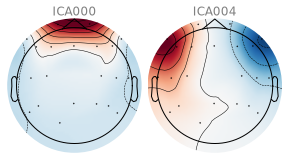

Windows kept at Fz: 1: Write, right (dominant): 100%, 2: Write, left (non-dominant): 99%


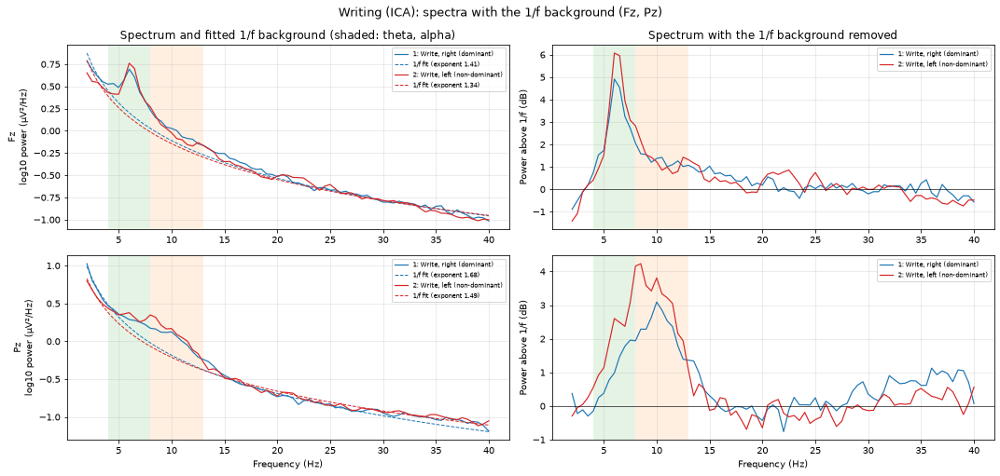

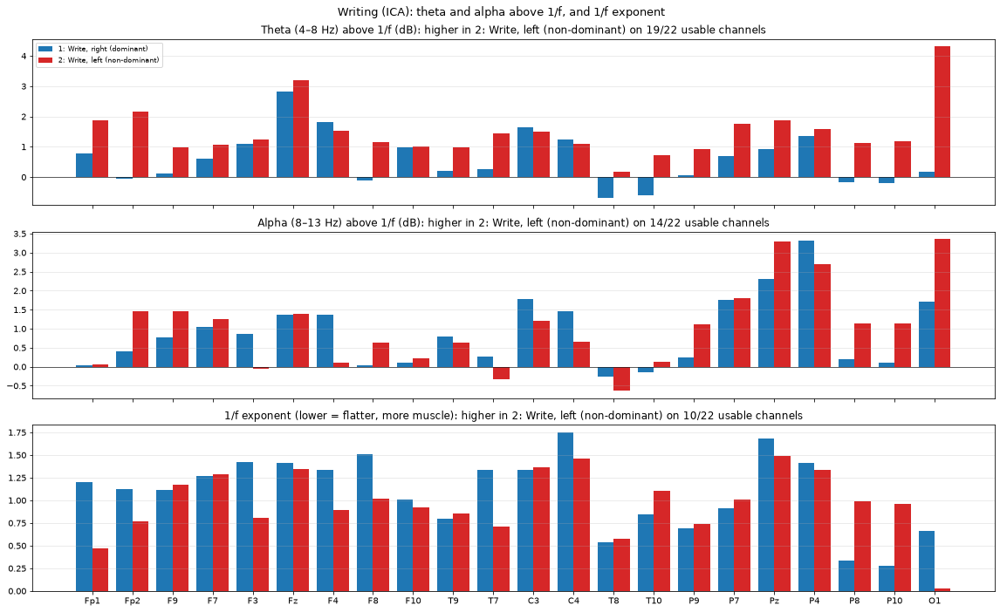

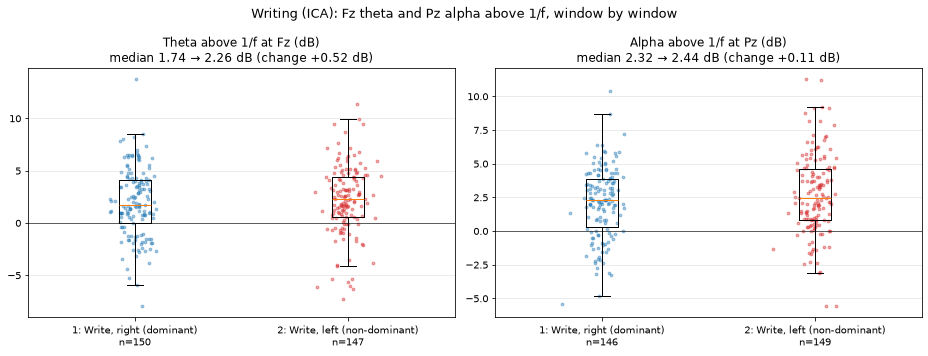

,"1: Write, right (dominant)","2: Write, left (non-dominant)",change_dB,descriptive_p_higher,descriptive_p_lower,n
measure,,,,,,
Theta above 1/f at Fz (dB),1.74,2.26,0.52,0.2,0.8,150 / 147
Alpha above 1/f at Pz (dB),2.32,2.44,0.11,0.1,0.9,146 / 149


In [27]:
writing_clean, writing_report, writing_ica = ica_clean(prepared[0:2])
show_cleaned_pair(writing_clean, writing_ica, writing_report, labels_writing, "Writing (ICA)")

### 6.2 Throwing: ASR, then ICA

**Why these plots:** the large jolt from each throw made this pair untestable in section 4.
Re-referencing to the average removes much of it (the jolt hits every channel at once) and ASR
repairs what remains; the plots then check the same workload markers as for writing.

Fz windows kept before ASR: ['93%', '80%'] → after ASR: ['93%', '92%']


ICA: 3 of 21 components removed: IC01 eye blink (1.00), IC04 eye blink (0.90), IC05 eye blink (0.85)


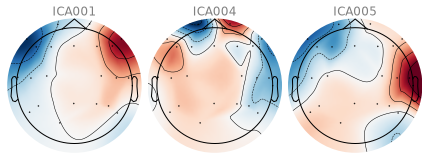

Windows kept at Fz: 5: Throw, right (dominant): 93%, 6: Throw, left (non-dominant): 92%


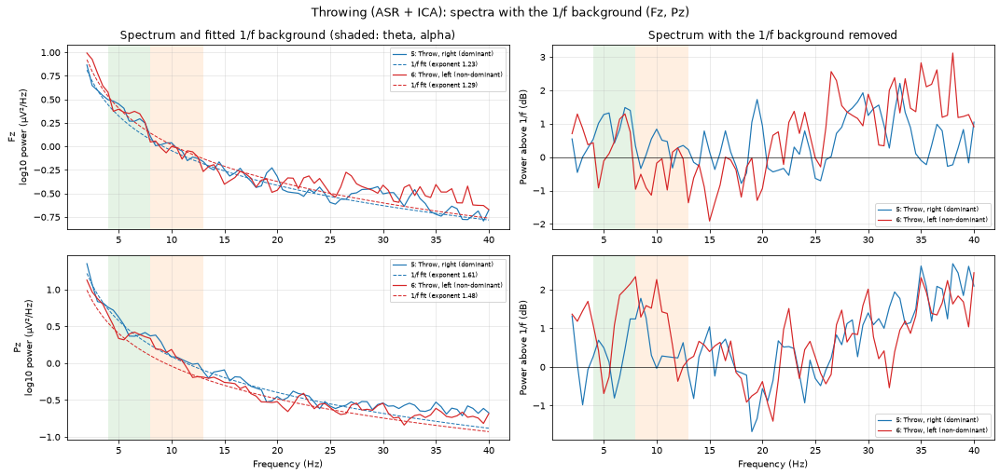

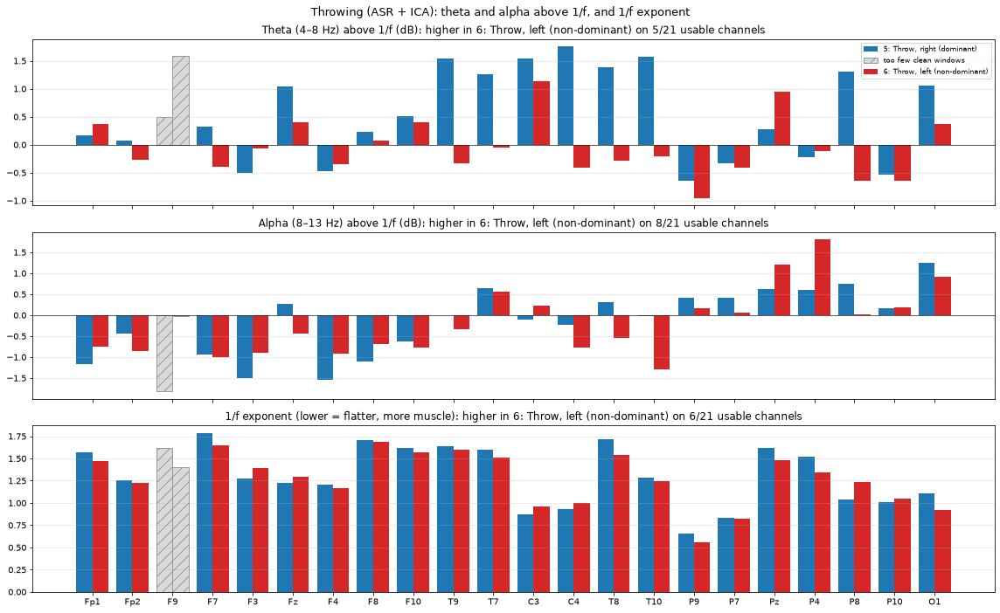

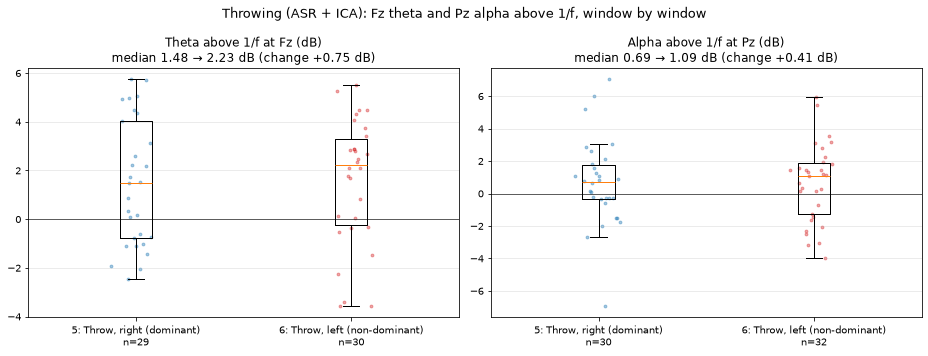

,"5: Throw, right (dominant)","6: Throw, left (non-dominant)",change_dB,descriptive_p_higher,descriptive_p_lower,n
measure,,,,,,
Theta above 1/f at Fz (dB),1.48,2.23,0.75,0.36,0.65,29 / 30
Alpha above 1/f at Pz (dB),0.69,1.09,0.41,0.42,0.58,30 / 32


In [28]:
throwing_asr = asr_clean(prepared[4:6], asr_calibration)
print("Fz windows kept before ASR:", fz_kept(prepared[4:6]), "→ after ASR:", fz_kept(throwing_asr))
throwing_clean, throwing_report, throwing_ica = ica_clean(throwing_asr)
show_cleaned_pair(throwing_clean, throwing_ica, throwing_report, labels_throwing, "Throwing (ASR + ICA)")

### 6.3 Juggling: ASR attempt

**Why this check:** the 3-packet segment had almost no clean data; this shows whether ASR can
recover enough of it to compare with the 1-packet segment.

In [29]:
juggling_asr = asr_clean(prepared[2:4], asr_calibration)
print("Fz windows kept before ASR:", fz_kept(prepared[2:4]), "→ after ASR:", fz_kept(juggling_asr))
periodic_workload_comparison([window_spectra(s, overlap=0.0) for s in juggling_asr], labels_juggling,
                             "Juggling (ASR): Fz theta and Pz alpha above 1/f")

Fz windows kept before ASR: ['85%', '10%'] → after ASR: ['93%', '59%']


Not enough clean Fz windows: 3: Juggle 1 packet (easy) n=28, 4: Juggle 3 packets (difficult) n=18 (need ≥20). Skipped.


## 7. Results: does the data support the hypothesis?

**No clear support in this session. Writing with the non-dominant hand shows at most a small
frontal theta increase and no parietal alpha decrease; throwing gives inconsistent results;
juggling can't be tested.**

| Pair (cleaned, above 1/f) | Usable after cleaning? | Fz theta, harder vs easier | Pz alpha, harder vs easier |
|---|---|---|---|
| **A: Writing** (ICA) | Yes, ~100% clean | +0.4 dB (averaged spectrum), +0.5 dB (window median, descriptive p = 0.2): small | **Higher**, not lower: +1.0 dB (averaged), +0.1 dB (window median) |
| **C: Throwing** (ASR + ICA) | Yes: Fz 93% / 92% clean (38% / 46% in the uncleaned data of section 4) | **Inconsistent:** −0.6 dB (averaged) but +0.75 dB (window median, p = 0.36) | Higher: +0.6 dB (averaged), +0.4 dB (median) |
| **B: Juggling** (ASR) | **No:** 3-packet only 59% clean at Fz after re-referencing + ASR (18 windows, need 20) | Not testable | Not testable |

How to read this:
- **Writing: theta above 1/f is higher with the left hand on 19 of 22 channels, but only
  slightly at Fz (+0.4 dB),** the main workload site. So there may be a weak, widespread theta
  increase, but not the clear frontal-midline effect the hypothesis predicts. (O1's large
  value is not trustworthy: its segment 2 spectrum is almost flat, exponent ≈ 0, so the 1/f fit fails there.)
- **Compared with Session 1** (Fz theta +1.4 to +3.1 dB, Pz alpha −0.6 to −0.9 dB after the
  same cleaning), the writing effect here is much smaller and the alpha change goes the wrong
  way. Writing your own name with the other hand is harder motorically, but it may not load
  working memory much, especially after already doing it once in Session 1.
- **Cleaning makes the throwing data usable.** Most of the gain comes from re-referencing to the
  average (part of preparing for ICA): each throw's jolt hits all channels at once, so
  subtracting the average removes much of it (Fz 38% / 46% → 93% / 80% clean). ASR then repairs
  the rest (→ 93% / 92%). But with ~30 windows per throw segment, the two estimates (averaged
  spectrum vs window median) disagree in sign, so there is no reliable effect.
- **Relative power (sections 2–4) and the overview (section 5) use uncleaned data;** the
  numbers in this section supersede them.
- **Same caveats as Session 1:** the harder task always came second, this is one person in one
  session, and harder motor tasks bring more muscle activity, which no cleaning fully removes.

**Next steps:**
- Record a rest baseline and subjective effort ratings (e.g. NASA-TLX) with each task, and
  counterbalance the task order.
- For the hand comparisons, a more direct measure than workload is **motor lateralization**:
  beta/mu power over the hemisphere opposite the moving hand (C3 for the right hand, C4 for
  the left) should drop during movement.